# Lab 09: ABC on a contaminated Hubble diagram

**ASTR 457, Fall 2026, posted Tue Nov 10, due Tue Nov 17 by noon (fork → PR, as always)**

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

NETID = 'zahisr2'   # <-- set this
LAB = '../../labs/09/data/'                              # from submissions/<your netid>/
d = pd.read_csv(LAB + f'{NETID}.csv')                    # columns: z, m_B, sigma_m
z, m, sig_m = d['z'].to_numpy(), d['m_B'].to_numpy(), d['sigma_m'].to_numpy()

## Part 1: Look first, then write the simulator (20%)

In [3]:
# Part 1: your work here
from astropy.cosmology import FlatLambdaCDM

z_grid = np.linspace(0.005, 0.75, 1500)
Om_grid = np.arange(0.05, 0.7001, 0.005)
mu_table = np.array([FlatLambdaCDM(H0=70, Om0=Om).distmod(z_grid).value for Om in Om_grid])

def mu_of(z, Om):
    j = np.clip(np.searchsorted(Om_grid, Om) - 1, 0, len(Om_grid) - 2)
    t = (Om - Om_grid[j]) / (Om_grid[j + 1] - Om_grid[j])
    return np.interp(z, z_grid, (1 - t) * mu_table[j] + t * mu_table[j + 1])

zt = np.array([0.011, 0.1, 0.35, 0.69])
for Om in [0.07, 0.2213, 0.3, 0.6871]:
    print(f'Om = {Om}: max |table - astropy| = {np.abs(mu_of(zt, Om) - FlatLambdaCDM(H0=70, Om0=Om).distmod(zt).value).max():.1e} mag')

Om = 0.07: max |table - astropy| = 1.5e-04 mag
Om = 0.2213: max |table - astropy| = 1.5e-04 mag
Om = 0.3: max |table - astropy| = 1.5e-04 mag
Om = 0.6871: max |table - astropy| = 1.5e-04 mag


In [4]:
print('faintest mB:', np.sort(m)[-5:])
print('largest z:', z.max())

faintest mB: [22.492048 22.493837 22.495009 22.49712  22.497406]
largest z: 0.454586


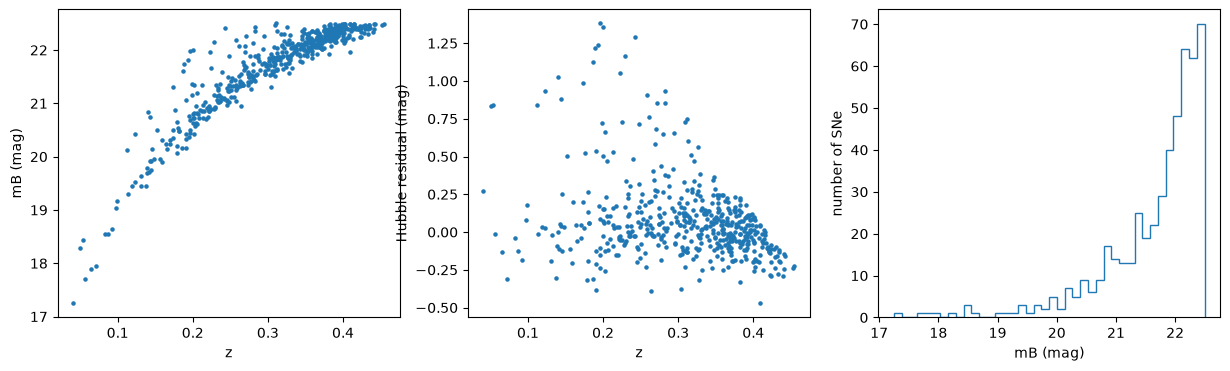

In [5]:
def plot_panels(z, m, axes, **kw):
    axes[0].scatter(z, m, s=5, **kw)
    axes[1].scatter(z, m - (-19.30) - mu_of(z, 0.3), s=5, **kw)
    axes[2].hist(m, bins=40, histtype='step', **kw)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
plot_panels(z, m, axes, label='data')
axes[0].set_xlabel('z'); axes[0].set_ylabel('mB (mag)')
axes[1].set_xlabel('z'); axes[1].set_ylabel('Hubble residual (mag)')
axes[2].set_xlabel('mB (mag)'); axes[2].set_ylabel('number of SNe')
plt.show()

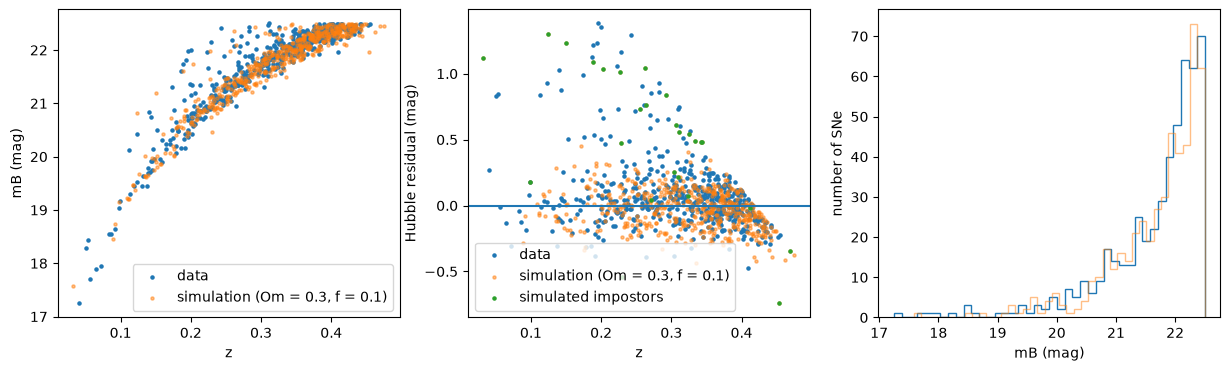

In [6]:
def simulate(Om, f, rng, n=500, n_draw=6000, m_lim=22.5):
    z = (0.01**3 + rng.random(n_draw) * (0.7**3 - 0.01**3))**(1 / 3)
    imp = rng.random(n_draw) < f
    M = np.where(imp, rng.normal(-18.5, 0.5, n_draw), rng.normal(-19.30, 0.12, n_draw))
    m = M + mu_of(z, Om) + rng.normal(0, 0.10, n_draw)
    keep = m < m_lim
    return z[keep][:n], m[keep][:n], imp[keep][:n]

rng = np.random.default_rng(1)
z_sim, m_sim, imp_sim = simulate(0.3, 0.1, rng)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
plot_panels(z, m, axes, label='data')
plot_panels(z_sim, m_sim, axes, alpha=0.5, label='simulation (Om = 0.3, f = 0.1)')
axes[1].scatter(z_sim[imp_sim], (m_sim - (-19.30) - mu_of(z_sim, 0.3))[imp_sim], s=5, label='simulated impostors')
axes[1].axhline(0)
axes[0].set_xlabel('z'); axes[0].set_ylabel('mB (mag)')
axes[1].set_xlabel('z'); axes[1].set_ylabel('Hubble residual (mag)')
axes[2].set_xlabel('mB (mag)'); axes[2].set_ylabel('number of SNe')
axes[0].legend(); axes[1].legend()
plt.show()

**ANSWER (what you see in the data, your graph, and what your simulator does):**

All 500 supernovae have sigma_m = 0.10 mag, as described. The file has one thing the description doesn't mention: nothing is fainter than mB = 22.5 (the faintest is 22.497, and the next four are all above 22.49), and the redshifts stop at z = 0.455 even though p(z) ∝ z² should put most supernovae between 0.5 and 0.7. The survey only kept supernovae brighter than mB = 22.5. In the residual plot most points lie in a band around zero, with about 40 points 0.5 mag or more above it, which look like impostors. They thin out at high z because, being about 0.8 mag fainter, they hit the cut sooner than the Ia do. I put the cut into the simulator, since it's part of how my file was made, so f is the impostor fraction before the cut.

![alt text](pgm_lab09-1.jpeg)

Om and f are the parameters. Each supernova has a latent type T_i, a latent absolute magnitude M_i drawn from the Ia or impostor population depending on T_i, a latent distance modulus mu_i set by Om and z_i, and a latent detection flag I_i set by mB_i and the fixed limit of 22.5. z_i and mB_i are data, and only for the supernovae with I_i = 1. f enters only through T_i, and Om only through mu_i.

The simulator follows the graph from top to bottom. It draws 6000 redshifts by inverting the z³ cumulative distribution, flags each supernova as an impostor with probability f, draws M from the matching population, adds the tabulated distance modulus and 0.10 mag of noise, keeps the ones with mB < 22.5, and returns the first 500.

## Part 2: The fit you'd do without thinking (15%)

Om = 0.201 +0.013 -0.013, chi2_min = 1585 for 499 dof


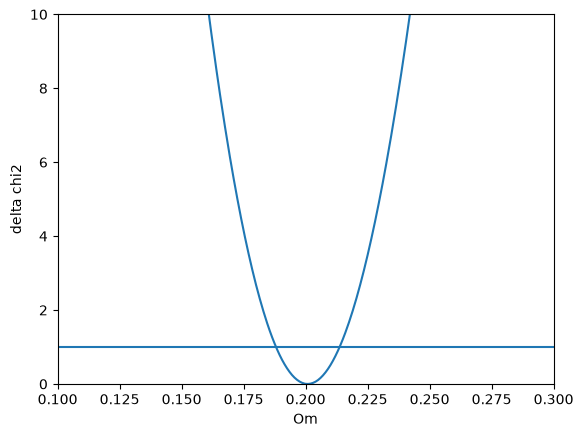

In [7]:
# Part 2: your work here
Om_fit = np.arange(0.05, 0.7, 0.0005)
sig_tot2 = 0.12**2 + 0.10**2
chi2 = np.array([np.sum((m - (-19.30) - mu_of(z, Om))**2) / sig_tot2 for Om in Om_fit])
Om_best = Om_fit[chi2.argmin()]
inside = Om_fit[chi2 < chi2.min() + 1]
print(f'Om = {Om_best:.3f} +{inside.max() - Om_best:.3f} -{Om_best - inside.min():.3f}, chi2_min = {chi2.min():.0f} for {len(z) - 1} dof')

plt.plot(Om_fit, chi2 - chi2.min())
plt.axhline(1)
plt.xlim(0.1, 0.3); plt.ylim(0, 10)
plt.xlabel('Om'); plt.ylabel('delta chi2')
plt.show()

**ANSWER (the naive fit, then why the impostors push it the way they do):**

Assuming everything is a Ia gives Om = 0.201 ± 0.013, but χ²_min = 1585 for 499 degrees of freedom, so the model doesn’t describe the data.

The impostors sit above the Ia line in the residual plot, about 0.8 mag fainter on average. The fit holds M at −19.30, so a supernova that looks fainter looks farther away. The only freedom it has to make supernovae farther away at a given z is to lower Om (less matter means less deceleration, which means a larger luminosity distance). The impostors therefore pull Om down. The pull comes from redshifts where the curves for different Om have separated, around z = 0.15 to 0.35. Below that, every Om gives nearly the same mu, so low-z impostors only add to χ². The impostors also thin out above z ≈ 0.35, because the 22.5 cut removes the fainter impostors first. So the faint excess is concentrated at intermediate z and missing at high z, and that shape is what the fit tries to absorb by changing Om.

## Part 3: ABC (40%)

In [8]:
# Part 3: your work here
def summaries(z, m):
    r = m - (-19.30) - mu_of(z, 0.3)
    return np.array([np.median(r[z > 0.3]), np.mean(r > 0.4)])

S_obs = summaries(z, m)
print('data summaries:', S_obs)

rng = np.random.default_rng(0)
N_sim = 50000
Om_prior = rng.uniform(0.05, 0.7, N_sim)
f_prior = rng.uniform(0, 0.5, N_sim)
S_sim = np.array([summaries(*simulate(Om_prior[i], f_prior[i], rng)[:2]) for i in range(N_sim)])
np.savez('abc_sims.npz', Om=Om_prior, f=f_prior, S=S_sim)

data summaries: [0.00355842 0.088     ]


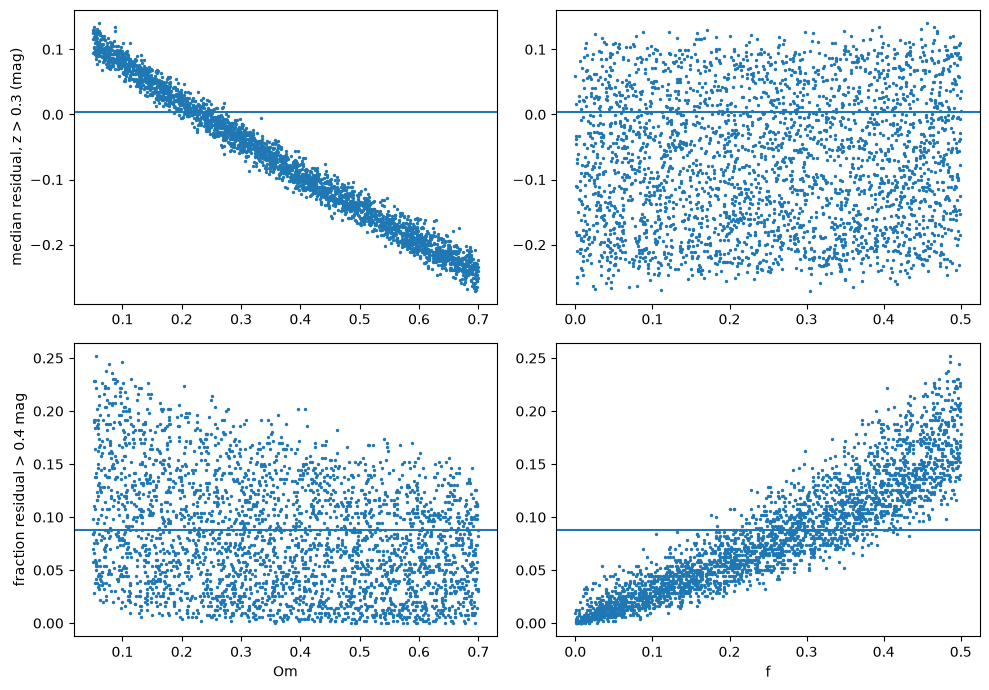

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
names = ['median residual, z > 0.3 (mag)', 'fraction residual > 0.4 mag']
for k in range(2):
    axes[k, 0].scatter(Om_prior[:3000], S_sim[:3000, k], s=2)
    axes[k, 1].scatter(f_prior[:3000], S_sim[:3000, k], s=2)
    axes[k, 0].axhline(S_obs[k]); axes[k, 1].axhline(S_obs[k])
    axes[k, 0].set_ylabel(names[k])
axes[1, 0].set_xlabel('Om'); axes[1, 1].set_xlabel('f')
plt.tight_layout()
plt.show()

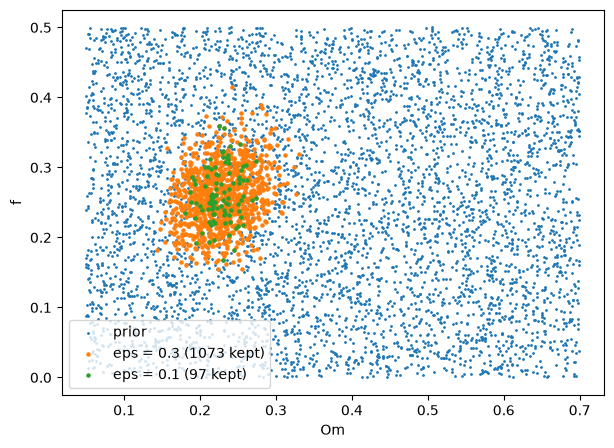

In [10]:
scale = S_sim.std(axis=0)
dist = np.sqrt(np.sum(((S_sim - S_obs) / scale)**2, axis=1))

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(Om_prior[:5000], f_prior[:5000], s=1, label='prior')
for eps in [0.3, 0.1]:
    keep = dist < eps
    ax.scatter(Om_prior[keep], f_prior[keep], s=5, label=f'eps = {eps} ({keep.sum()} kept)')
ax.set_xlabel('Om'); ax.set_ylabel('f')
ax.legend()
plt.show()

In [11]:
for eps in [0.5, 0.3, 0.2, 0.1, 0.05]:
    keep = dist < eps
    Om_q = np.percentile(Om_prior[keep], [2.5, 50, 97.5])
    f_q = np.percentile(f_prior[keep], [2.5, 50, 97.5])
    print(f'eps = {eps}: {keep.sum()} kept, Om = {Om_q[1]:.3f} ({Om_q[0]:.3f}-{Om_q[2]:.3f}), f = {f_q[1]:.3f} ({f_q[0]:.3f}-{f_q[2]:.3f})')

keep = dist < 0.1

eps = 0.5: 3051 kept, Om = 0.231 (0.142-0.319), f = 0.257 (0.165-0.360)
eps = 0.3: 1073 kept, Om = 0.228 (0.166-0.292), f = 0.257 (0.181-0.342)
eps = 0.2: 450 kept, Om = 0.227 (0.174-0.280), f = 0.258 (0.186-0.336)
eps = 0.1: 97 kept, Om = 0.228 (0.189-0.266), f = 0.256 (0.193-0.332)
eps = 0.05: 24 kept, Om = 0.226 (0.198-0.257), f = 0.265 (0.176-0.318)


In [12]:
for name, v in [('Om', Om_prior[keep]), ('f', f_prior[keep])]:
    lo, med, hi = np.percentile(v, [16, 50, 84])
    print(f'{name} = {med:.3f} +{hi - med:.3f} -{med - lo:.3f} (68%)')

Om = 0.228 +0.023 -0.018 (68%)
f = 0.256 +0.045 -0.032 (68%)


**ANSWER (your summaries and why, the two epsilons, the posterior, and the comparison with Part 2):**
I used two summaries of the Hubble residuals against Om = 0.3. The median residual above z = 0.3 tracks Om: the 22.5 cut has removed almost every impostor by then, so it measures where the Ia line sits, and the Om curves have separated by those redshifts. The fraction of residuals above 0.4 mag tracks f, since a Ia lands that far above the line only about 2% of the time while impostors sit near +0.8 mag. The plots above show each summary following one parameter and barely responding to the other.

The summaries have different units, so I divided each by its standard deviation over the prior simulations before taking the Euclidean distance. The kept draws at both ε form a blob well inside the prior, with no pile-up at an edge.

I chose ε = 0.1 (97 kept). The medians stay the same from ε = 0.5 down to 0.1 while the intervals narrow, and at 0.05 too few draws are left for a stable 95% interval. At ε = 0.1, Om = 0.228 +0.023 −0.018 and f = 0.256 +0.045 −0.031 (medians with 68% intervals), and the 95% intervals are 0.189–0.266 and 0.193–0.332. The naive χ² fit gave 0.201 ± 0.013, which is lower, as 2.2 predicted, and its 68% interval misses the ABC median. The ABC interval is wider because it has to account for the impostors instead of assuming there are none.

## Part 4: Check it (15%)

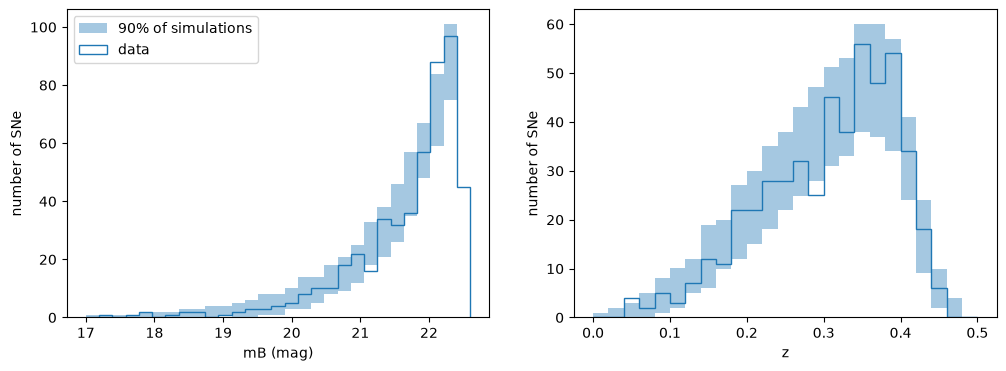

In [13]:
# Part 4: your work here
rng = np.random.default_rng(2)
idx = rng.choice(np.where(keep)[0], 100)
bins_m = np.linspace(17, 22.6, 30)
bins_z = np.linspace(0, 0.5, 26)
h_m, h_z = [], []
for i in idx:
    z_s, m_s, _ = simulate(Om_prior[i], f_prior[i], rng)
    h_m.append(np.histogram(m_s, bins_m)[0])
    h_z.append(np.histogram(z_s, bins_z)[0])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, h, b, x, lab in [(axes[0], h_m, bins_m, m, 'mB (mag)'), (axes[1], h_z, bins_z, z, 'z')]:
    lo, hi = np.percentile(h, [5, 95], axis=0)
    ax.fill_between(b[:-1], lo, hi, step='post', alpha=0.4, label='90% of simulations')
    ax.hist(x, b, histtype='step', label='data')
    ax.set_xlabel(lab); ax.set_ylabel('number of SNe')
axes[0].legend()
plt.show()

In [14]:
n_cov = 100
hits, n_kept = [], []
for i in range(n_cov):
    dist_i = np.sqrt(np.sum(((S_sim - S_sim[i]) / scale)**2, axis=1))
    dist_i[i] = np.inf
    k = dist_i < 0.1
    n_kept.append(k.sum())
    Om_lo, Om_hi = np.percentile(Om_prior[k], [2.5, 97.5])
    f_lo, f_hi = np.percentile(f_prior[k], [2.5, 97.5])
    hits.append([Om_lo < Om_prior[i] < Om_hi, f_lo < f_prior[i] < f_hi])
hits = np.array(hits)
print(f'Om covered {hits[:, 0].mean():.2f}, f covered {hits[:, 1].mean():.2f}, kept per run: min {min(n_kept)}, median {np.median(n_kept):.0f}')

Om covered 0.94, f covered 0.91, kept per run: min 2, median 143


**ANSWER (the check, the coverage, and the assumption):**

For 100 kept draws I simulated a new file and compared the histograms of mB and z with my data. ABC never used either. My data stay inside the range of the simulations in almost every bin, including the sharp drop at 22.5 and the end of the redshifts near 0.45, so my data look like a typical simulation.

For coverage I treated each of 100 prior simulations as the data and reran ABC with the other simulations. The 95% interval held the true Om in 94% and the true f in 91% of runs. With 100 trials, anything from about 91% to 99% is consistent with 95%, so the intervals are honest. A few runs kept as few as 2 draws, when the fake truth was near a corner of the prior.

My simulator assumes the impostor fraction f is the same at every redshift. A real light-curve classifier does worse on faint, noisy light curves, so more impostors get through at high z. Extra impostors above z = 0.3 would push the median residual there upward (fainter), and my simulator would read that as a lower Om. Om would come out biased low.

## Part 5: AI-use appendix and verification plan (10%)

1. **AI use**: which tools, for what, what they got wrong, and how you caught it. "I didn't use any" is fine if true.
2. **Reflection**: what would have gone wrong in your answer if you had not checked the AI's output? Name the specific thing.
3. **Verification plan**: the checks you ran before trusting your Part 3 numbers, and what failure would have looked like for each. Part 4.2 is already one. Another to consider: simulate a dataset at an $(\Omega_m, f)$ you choose, run your whole ABC on it, and see whether you get back what you put in.

In [15]:
rng = np.random.default_rng(5)
for Om_true, f_true in [(0.35, 0.15), (0.25, 0.30), (0.50, 0.05)]:
    z_t, m_t, _ = simulate(Om_true, f_true, rng)
    k = np.sqrt(np.sum(((S_sim - summaries(z_t, m_t)) / scale)**2, axis=1)) < 0.1
    Om_q = np.percentile(Om_prior[k], [2.5, 50, 97.5])
    f_q = np.percentile(f_prior[k], [2.5, 50, 97.5])
    print(f'true ({Om_true}, {f_true}): Om = {Om_q[1]:.3f} ({Om_q[0]:.3f}-{Om_q[2]:.3f}), f = {f_q[1]:.3f} ({f_q[0]:.3f}-{f_q[2]:.3f}), {k.sum()} kept')

true (0.35, 0.15): Om = 0.364 (0.323-0.404), f = 0.127 (0.080-0.189), 161 kept
true (0.25, 0.3): Om = 0.260 (0.216-0.302), f = 0.300 (0.246-0.380), 108 kept
true (0.5, 0.05): Om = 0.541 (0.494-0.586), f = 0.024 (0.002-0.077), 227 kept


**AI-USE APPENDIX:**

I used Claude to plan and write the code for each part (the distance-modulus table, the simulator, the summaries, the ABC loop and the checks) after first working with it to understand the physical context of the problems and informing it about the things we went over in lecture - this was done to make sure I both knew what we were covering before implementing and submitting them with AI, as well as to study the content for quizzes. After I ran every cell I made sure to check every number and plot as AI cannot see the output or the numbers from the code it generated. This manual checking found errors like the one discused below. I also used google AI overview on how to drag the pgm images into notebooks because it was not cooperating.

**REFLECTION:**

Claude’s first simulator left out the mB < 22.5 cut. It ran without errors, but plotted over my data it went much fainter and farther than my supernovae. ABC would have fit my file with the wrong kind of survey, and coverage wouldn’t have caught it, since that only tests the simulator against itself. I caught it by plotting a simulation over my data before running ABC and had to inform claude of the error, and why even though the code was an easy fix, it was important for it to understand that error in context before further work.

**VERIFICATION PLAN:**

- Distance-modulus table vs astropy (failure: a difference anywhere near the 0.10 mag errors).
- Simulation plotted over my data (failure: a visible mismatch in any panel).
- Each summary plotted against Om and f (failure: both follow the same parameter).
- Kept draws away from the prior edges (failure: piled against an edge).
- Full ABC on fake files at three chosen (Om, f): all recovered inside their 95% intervals (failure: truth outside the interval).
- Coverage: 94% for Om and 91% for f (failure: well below 95%).